# Shock tubes: Toro's tests 1-5 against the exact Riemann solution

Toro (2009, *Riemann Solvers and Numerical Methods for Fluid Dynamics*, Table 4.1) defines five
1D Riemann problems (gamma = 1.4): a Sod-like tube, two strong rarefactions (123 problem), two
strong shocks, and the collision of two shocks. Each is run with LUNA's two Riemann solvers,
HLLC (the default) and HLL, at 128 cells, FP64, PLM with the minmod limiter, and compared with
the exact solution (`luna.hydro.exact_riemann`, Toro ch. 4), averaged over each cell.

What is compared: L1 of density, velocity and pressure, next to the values that the test
`tests/test_hydro_accuracy_shocktube.py` measured for the same runs, and the convergence of
test 1 over 128-512 cells. The grids are small; the test runs 128, 256, 512 per case and
also checks front positions and the exact conservation budget.

Runtime: about 1.5 minutes on four CPU cores (an A100 node's CPU cores via SLURM, JAX on the CPU), including JAX start-up and compilation, which dominate.

In [1]:
import os
os.environ.setdefault("JAX_PLATFORMS", "cpu")   # this notebook is sized for a CPU; unset it to use a GPU

import contextlib, io, time
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from luna import Config, launch


def run(cfg, **state):
    """launch(cfg, **state), as `python main.py` runs it (state: U0= or ic=, an initial state of our own),
    with its log kept out of the notebook; (RunResult, wall s)."""
    t0 = time.time()
    with contextlib.redirect_stdout(io.StringIO()):
        res = launch(cfg, **state)
    return res, time.time() - t0


# FP64, PLM, HLLC, quiet: the settings of LUNA's accuracy tests
QUIET = dict(enable_x64=True, ORDER=1, LIMITER=0, riemann_solver="hllc", PLOT_AFTER_SIM=False,
             output_cadence=10**6, diag_interval=10**6, enable_checkpointing=False, clear_output_dir=True)
BASE = replace(Config(), **QUIET)

**A custom initial state through the run path.** LUNA's registered problems (`test_problem`) fix
their initial states. A state of our own goes to `launch(cfg, U0=U)`: `U` holds the conserved
variables on the whole grid in the run's own dimension, `(3, Nx)` in 1D (rho, rho vx, E),
`(4, Nx, Ny)` in 2D, `(5, Nx, Ny, Nz)` in 3D, energy last; a shape that does not fit the config is
refused. It takes the path `python main.py` takes (`luna/ic_generation/user_ic.py`), sharded like a
registered problem; `test_problem` then only names the run.

In [2]:
from luna import conserved
from luna.hydro import exact_riemann as er

G = 1.4
base = replace(BASE, test_problem="Toro-Tube", SPATIAL_DIMENSION=1, Lx=1.0, BOUNDARY=1, gamma=G,
               write_snapshots=False)


def tube(W):
    """(rho, u, p) on n cells -> conserved (3, n): rho, rho u, E."""
    rho, u, p = W
    return conserved(rho, (u,), p, G)


def prim(U):
    """Conserved (3, n) -> (rho, u, p)."""
    V = np.asarray(U, np.float64)
    rho, u = V[0], V[1] / V[0]
    return rho, u, (G - 1) * (V[2] - 0.5 * rho * u * u)


def toro(case, n, solver):
    """Numerical and exact cell-averaged (rho, u, p) of Toro test `case` at its end time."""
    WL, WR, x0, t = er.TORO[case]
    edges = np.linspace(0.0, 1.0, n + 1)
    U0 = tube(er.cell_average(WL, WR, G, edges, x0, 1e-12))
    cfg = replace(base, Nx=n, riemann_solver=solver, t_end=t, output_dir="snapshots/nb03/run")
    res, wall = run(cfg, U0=U0)
    return prim(res.extra["U"]), er.cell_average(WL, WR, G, edges, x0, res.t), res, wall

In [3]:
# L1 (rho, u, p) measured by tests/test_hydro_accuracy_shocktube.py at N = 128 (CPU, FP64, minmod)
TEST_L1 = {("hllc", 1): (0.00483, 0.00749, 0.00365), ("hllc", 2): (0.00701, 0.0257, 0.00415),
           ("hllc", 3): (0.116, 0.256, 5.66), ("hllc", 4): (0.102, 0.0752, 0.537),
           ("hllc", 5): (0.349, 0.0999, 7.33),
           ("hll", 1): (0.00529, 0.00789, 0.00381), ("hll", 2): (0.00703, 0.0257, 0.00415),
           ("hll", 3): (0.118, 0.289, 6.34), ("hll", 4): (0.104, 0.0854, 0.603),
           ("hll", 5): (0.384, 0.11, 8.98)}

N = 128
out = {}
print("case solver  steps   L1 rho     L1 u       L1 p        (test: rho, u, p)")
for case in er.TORO:
    for solver in ("hllc", "hll"):
        num, ex, res, wall = toro(case, N, solver)
        l1 = [float(np.mean(np.abs(a - b))) for a, b in zip(num, ex)]
        out[case, solver] = (num, ex, l1)
        print(f"{case:4d} {solver:5s} {res.n_steps:6d}   " + "  ".join(f"{v:.3e}" for v in l1)
              + "   (" + ", ".join(f"{v:.3g}" for v in TEST_L1[solver, case]) + f")  {wall:.1f} s")

case solver  steps   L1 rho     L1 u       L1 p        (test: rho, u, p)


   1 hllc      87   4.832e-03  7.491e-03  3.650e-03   (0.00483, 0.00749, 0.00365)  2.3 s


   1 hll       87   5.288e-03  7.893e-03  3.812e-03   (0.00529, 0.00789, 0.00381)  0.9 s


   2 hllc      66   7.008e-03  2.574e-02  4.148e-03   (0.00701, 0.0257, 0.00415)  1.2 s


   2 hll       66   7.027e-03  2.569e-02  4.148e-03   (0.00703, 0.0257, 0.00415)  1.0 s


   3 hllc     103   1.155e-01  2.561e-01  5.662e+00   (0.116, 0.256, 5.66)  1.2 s


   3 hll      102   1.181e-01  2.886e-01  6.344e+00   (0.118, 0.289, 6.34)  0.9 s


   4 hllc      95   1.017e-01  7.518e-02  5.371e-01   (0.102, 0.0752, 0.537)  1.3 s


   4 hll       94   1.038e-01  8.539e-02  6.031e-01   (0.104, 0.0854, 0.603)  0.9 s


   5 hllc     168   3.491e-01  9.990e-02  7.335e+00   (0.349, 0.0999, 7.33)  1.1 s


   5 hll      168   3.838e-01  1.097e-01  8.978e+00   (0.384, 0.11, 8.98)  0.9 s


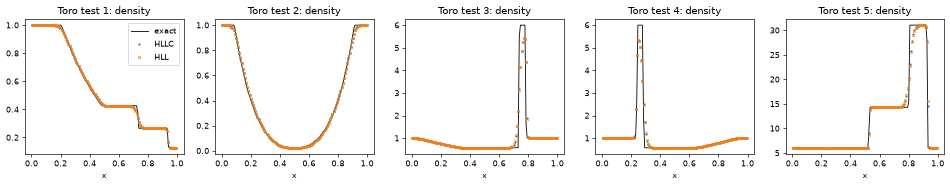

In [4]:
x = (np.arange(N) + 0.5) / N
fig, ax = plt.subplots(1, 5, figsize=(16, 3.2), dpi=60)
for a, case in zip(ax, er.TORO):
    a.plot(x, out[case, "hllc"][1][0], "k-", lw=1, label="exact")
    a.plot(x, out[case, "hllc"][0][0], ".", ms=3, label="HLLC")
    a.plot(x, out[case, "hll"][0][0], "x", ms=3, label="HLL")
    a.set_title(f"Toro test {case}: density"); a.set_xlabel("x")
ax[0].legend()
fig.tight_layout()

Convergence of test 1 (HLLC): with a shock and a contact the L1 error falls as about N^-0.8,
not N^-2 (discontinuities are smeared over a fixed number of cells).

Toro 1, HLLC, L1(rho): N=128: 4.832e-03, N=256: 2.654e-03, N=512: 1.539e-03 ; order 0.83
the test measured 0.00483, 0.00265, 0.00154 and the order 0.825 over 128-512


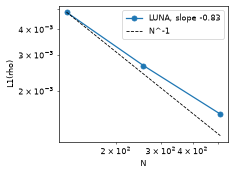

In [5]:
ns = (128, 256, 512)
l1 = [float(np.mean(np.abs(num[0] - ex[0]))) for num, ex, *_ in (toro(1, n, "hllc") for n in ns)]
order = -np.polyfit(np.log(ns), np.log(l1), 1)[0]
print("Toro 1, HLLC, L1(rho):", ", ".join(f"N={n}: {v:.3e}" for n, v in zip(ns, l1)), f"; order {order:.2f}")
print("the test measured 0.00483, 0.00265, 0.00154 and the order 0.825 over 128-512")
fig, a = plt.subplots(figsize=(4, 3), dpi=60)
a.loglog(ns, l1, "o-", label=f"LUNA, slope -{order:.2f}")
a.loglog(ns, l1[0] * (ns[0] / np.array(ns)), "k--", lw=1, label="N^-1")
a.set_xlabel("N"); a.set_ylabel("L1(rho)"); a.legend()
fig.tight_layout()

**What this shows.** Through the run path, HLLC and HLL give the L1 errors that the test measured for all five Toro problems at 128 cells, to the three digits printed. Test 1 converges at order 0.83 over 128-512 cells (the test: 0.825): below 1, as expected with a shock and a contact. HLL is the more diffusive of the two at contacts (tests 1, 3, 4, 5).

Status (docs/CLAIMS.md): *validated*. "Shock tubes (Toro 1-5) converge to the exact Riemann
solution", `tests/test_hydro_accuracy_shocktube.py:157`; HLLC and HLL against their textbook
definitions, `tests/test_hydro_accuracy_riemann.py`.